Estimation error and backtest

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf

from quantlab.data_loader import load_prices
from quantlab.returns import log_returns
from quantlab.covariance import sample_cov, ledoit_wolf, ewma_cov, mp_edges, mp_density
from quantlab.simulation import one_factor_cov, excess_variance_study

stocks = log_returns(load_prices()).drop(columns="^GSPC")
print(stocks.shape)

(6537, 25)


250 edges: 0.47 1.73 | eigenvalues: 0.48 1.55
2500 edges: 0.81 1.21 | eigenvalues: 0.86 1.18


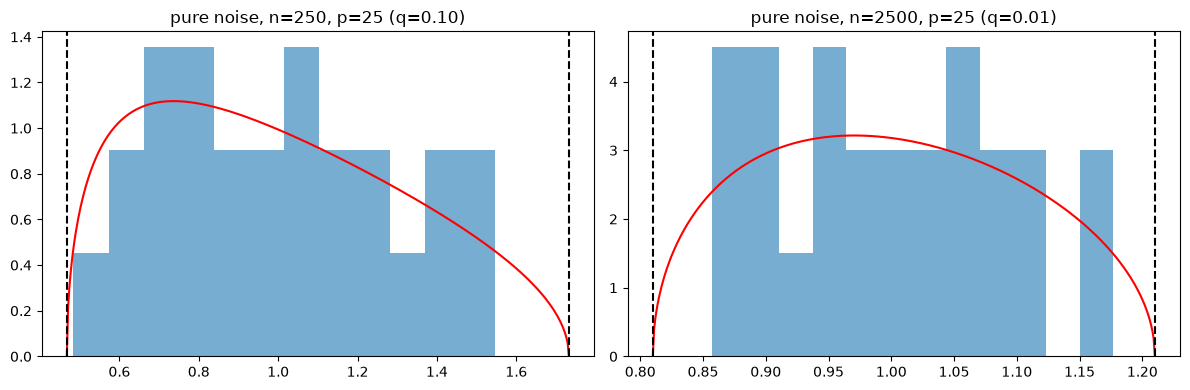

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, n in zip(ax, [250, 2500]):
    X = np.random.default_rng(0).standard_normal((n, 25))
    eig = np.linalg.eigvalsh(np.corrcoef(X, rowvar=False))
    lo, hi = mp_edges(n, 25)
    grid = np.linspace(lo, hi, 400)
    a.hist(eig, bins=12, density=True, alpha=0.6)
    a.plot(grid, mp_density(grid, n, 25), "r")
    a.axvline(lo, color="k", ls="--")
    a.axvline(hi, color="k", ls="--")
    a.set_title(f"pure noise, n={n}, p=25 (q={25 / n:.2f})")
    print(n, "edges:", round(lo, 2), round(hi, 2), "| eigenvalues:", eig.min().round(2), eig.max().round(2))
plt.tight_layout()
plt.show()

last 250 days | upper edge: 1.73 | largest eigenvalues: [7.94 3.41 1.48 1.3 ] | above edge: 2
full sample | upper edge: 1.13 | largest eigenvalues: [9.31 1.86 1.57 1.1 ] | above edge: 3


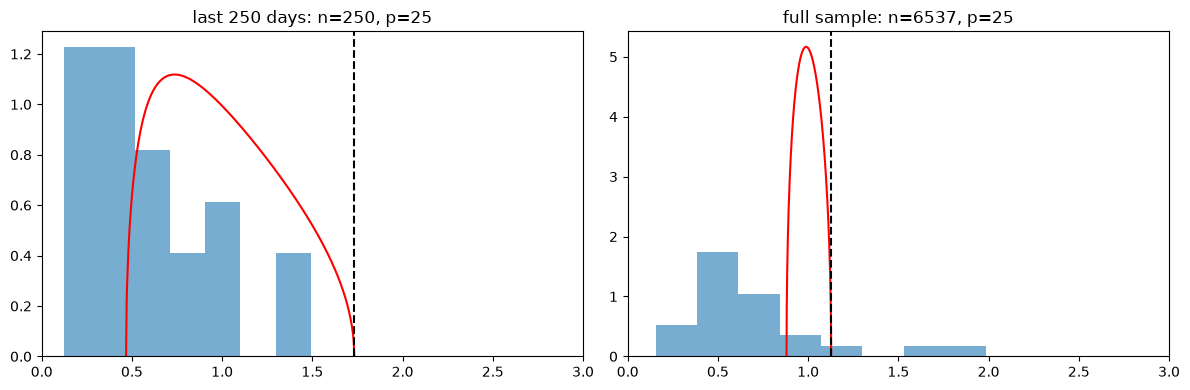

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (label, X) in zip(ax, [("last 250 days", stocks.iloc[-250:]), ("full sample", stocks)]):
    n, p = X.shape
    eig = np.linalg.eigvalsh(np.corrcoef(X.to_numpy(), rowvar=False))
    lo, hi = mp_edges(n, p)
    grid = np.linspace(lo, hi, 400)
    a.hist(eig, bins=40, density=True, alpha=0.6)
    a.plot(grid, mp_density(grid, n, p), "r")
    a.axvline(hi, color="k", ls="--")
    a.set_xlim(0, 3)
    a.set_title(f"{label}: n={n}, p={p}")
    print(label, "| upper edge:", round(hi, 2), "| largest eigenvalues:", np.sort(eig)[::-1][:4].round(2),
          "| above edge:", int((eig > hi).sum()))
plt.tight_layout()
plt.show()

In [4]:
for label, X in [("last 250 days", stocks.iloc[-250:]), ("full sample", stocks)]:
    A = X.to_numpy()
    S_lw, delta = ledoit_wolf(A)
    lw = LedoitWolf().fit(A)
    print(f"{label}: delta = {delta:.3f} (sklearn {lw.shrinkage_:.3f}), "
          f"max diff = {np.abs(S_lw - lw.covariance_).max():.1e}, "
          f"cond sample = {np.linalg.cond(sample_cov(A)):.0f}, cond LW = {np.linalg.cond(S_lw):.0f}")

last 250 days: delta = 0.139 (sklearn 0.139), max diff = 0.0e+00, cond sample = 109, cond LW = 34
full sample: delta = 0.006 (sklearn 0.006), max diff = 0.0e+00, cond sample = 89, cond LW = 85


In [5]:
true_cov = one_factor_cov(25, seed=0)
study = excess_variance_study(true_cov, ns=(60, 120, 250, 500, 1000), reps=500, seed=0)

print("Excess-variance ratio (1 = perfect):")
display(study.pivot(index="n", columns="estimator", values="ratio").round(3))
print("Condition number of the estimate:")
display(study.pivot(index="n", columns="estimator", values="cond").round(0))

Excess-variance ratio (1 = perfect):


estimator,ewma,ledoit_wolf,sample
n,,,
60,1.984,1.335,1.689
120,1.948,1.196,1.259
250,1.941,1.098,1.109
500,1.954,1.048,1.051
1000,1.939,1.023,1.024


Condition number of the estimate:


estimator,ewma,ledoit_wolf,sample
n,,,
60,251.0,61.0,155.0
120,230.0,53.0,73.0
250,229.0,46.0,51.0
500,230.0,42.0,44.0
1000,227.0,40.0,41.0


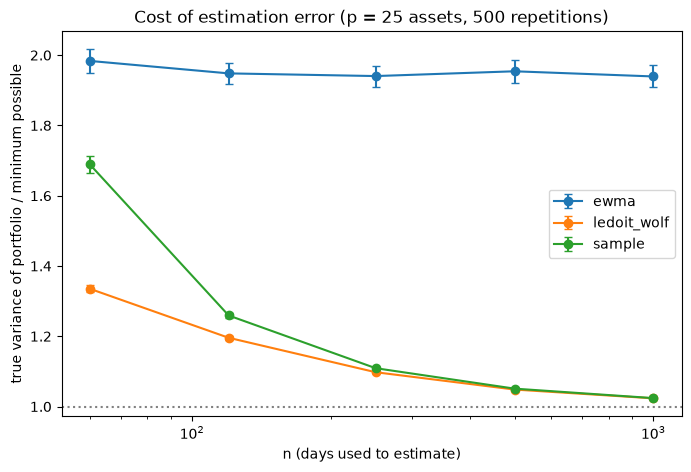

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in study.groupby("estimator"):
    ax.errorbar(g["n"], g["ratio"], yerr=2 * g["ratio_se"], marker="o", capsize=3, label=name)
ax.axhline(1, color="grey", ls=":")
ax.set_xscale("log")
ax.set_xlabel("n (days used to estimate)")
ax.set_ylabel("true variance of portfolio / minimum possible")
ax.set_title("Cost of estimation error (p = 25 assets, 500 repetitions)")
ax.legend()
plt.show()

## Conclusions (Part 1: estimation error)

**1. Marchenko-Pastur on pure noise.** For independent noise with p = 25, the sample correlation eigenvalues stay inside the predicted edges. With n = 250 (q = 0.10) the edges are 0.47 and 1.73 and the observed eigenvalues run from 0.48 to 1.55. With n = 2,500 (q = 0.01) the edges tighten to 0.81 and 1.21 and the observed range is 0.86 to 1.18. Even when the truth is the identity matrix, the sample eigenvalues are spread out: with 250 days the smallest comes out near half of the true value and the largest well above it. The spread shrinks as n grows relative to p.

**2. Real data against the edge.** In the last 250 days, the upper edge is 1.73, and two eigenvalues lie above it (7.94 and 3.41). The next two (1.48 and 1.30) are inside the bulk, so they cannot be separated from noise. In the full sample (n = 6,537), the edge is much tighter at 1.13, and three eigenvalues exceed it (9.31, 1.86 and 1.57). The largest eigenvalue is the market factor: 9.31 out of a total of 25 means it carries about 37% of the variance, consistent with the 38.6% PC1 share found in the PCA drill. The smaller eigenvalues above the edge probably reflect sector or period effects. Eigenvalues inside the bulk should not be trusted individually. A portfolio optimiser that uses them is fitting noise.

**3. Ledoit-Wolf on real data.** My implementation matches scikit-learn exactly (maximum difference 0.0 in both windows, and the same shrinkage values). With 250 days the intensity is δ = 0.139, so the estimate moves 14% of the way toward the scaled identity, and the condition number falls from 109 to 34. With the full sample, δ = 0.006 and the condition number is almost unchanged (89 to 85). Shrinkage matters when the sample is short relative to the number of assets (p/n = 0.10 here) and is almost irrelevant when it is long (p/n = 0.004).

**4. Simulation with a known truth (excess-variance ratio, 1 = perfect).** Building the minimum-variance portfolio from a sample covariance of 60 days gives a portfolio with 69% more true variance than the best possible one (ratio 1.689). Ledoit-Wolf reduces this to 1.335. At n = 120 the figures are 1.259 and 1.196, at n = 250 they are 1.109 and 1.098, and at n = 1,000 they are 1.024 and 1.023. Both converge to 1 as n grows, and Ledoit-Wolf is never worse than the sample estimator. The benefit is large when n is small and negligible when n is large, which agrees with the shrinkage intensities found on the real data. Condition numbers tell the same story: at n = 60 the sample covariance averages 155 and Ledoit-Wolf 61. The standard errors on these ratios are small (below 0.02), so the ordering is not a fluke of the draws.

**5. EWMA.** EWMA stays at a ratio of about 1.94 to 1.98 for every n, with a condition number of about 230, and does not improve as the sample grows. With λ = 0.94 the effective sample is only about 1/(1-λ) ≈ 17 days, which is fewer than the 25 assets, so its estimate stays noisy however much data is available. In this simulation the true covariance never changes, so EWMA's strength (reacting to changing volatility) cannot show. This says nothing yet about real data, where volatility clusters. Whether EWMA wins there is an empirical question for the backtest.

**6. Limits of this evidence.** The simulation uses Normal data, a stationary one-factor covariance and 25 assets. Real returns have fat tails and clustered volatility, so real estimation errors are probably larger than shown. The study also covers only the covariance matrix. The means, which drove the extreme tangency weights, are estimated with much more error and have not been tested here.